# EDA - HumAID, Kaggle "NLP with Disaster Tweets", CrisisLexT26

Covers every item of **EDA_Checklist_Three_Datasets.pdf** (sections A-E). Item IDs such as **A4** or **C2** refer to that checklist.

**How to run** (local or Colab): clone the repo, `pip install -r requirements.txt`, open this notebook, *Run All*. It reads the files in `data/raw/` (no uploads), never modifies raw data, uses the **same cleaning code as the production pipeline** (`src/preprocessing/text_cleaning.py`) and writes its evidence to `docs/eda/`.

| Section | Dataset role |
|---|---|
| A | checks run on all three datasets |
| B | HumAID - trains the primary classifier |
| C | Kaggle - trains the binary pre-filter |
| D | CrisisLexT26 - external evaluation only, never trained on |
| E | cross-dataset comparison |

The last cell is a **scorecard**: one row per checklist item with the measured finding and the resulting decision.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "data" / "raw").exists(), "Open this notebook from inside the cloned repository."
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from src.analysis import eda_utils as E
from src.analysis.run_audits import overlap, oov_stats
from src.preprocessing.text_cleaning import clean_tweet_for_tfidf, prepare_tweet_for_transformer, normalize_for_dedup
from src.preprocessing.vocabulary import build_vocabulary, tokenize_for_vocabulary
from src.preprocessing.config import BILSTM_MAX_SEQUENCE_LENGTH, BERTWEET_MAX_LENGTH, HUMAID_CARD_LABELS
from src.preprocessing.labels import CRISISLEX_LABEL_MAP, CRISISLEX_PREFILTER_MAP, describe_label_schema

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)
E.EDA_DIR.mkdir(parents=True, exist_ok=True)
summary = {}          # every measurement below is saved to docs/eda/eda_summary.json
print("repo root:", ROOT)

repo root: /content/Disaster_Response_Classifier


---
# SECTION A - Universal checks (all three datasets)

## A1 - Row counts
The HumAID splits are the official ones (never re-shuffled). The Kaggle file is the labeled `train` file only. CrisisLexT26 counts the **labeled** tweets in the 26 per-event files (the ~250k figure sometimes quoted is the full ID collection, not the labeled set).

In [2]:
humaid = E.load_humaid()
kaggle = E.load_kaggle()
crisislex, cl_schemas = E.load_crisislex()

expected = {"HumAID train": 53531, "HumAID validation": 7793, "HumAID test": 15160,
            "Kaggle labeled train": 7613, "CrisisLexT26 labeled (26 files)": 27933}
found = {"HumAID train": len(humaid["train"]), "HumAID validation": len(humaid["validation"]),
         "HumAID test": len(humaid["test"]), "Kaggle labeled train": len(kaggle),
         "CrisisLexT26 labeled (26 files)": len(crisislex)}
row_counts = pd.DataFrame({"found": found, "expected": expected}).assign(match=lambda d: d.found == d.expected)
display(row_counts)
summary["A1_row_counts"] = row_counts.reset_index().to_dict("records")
assert row_counts.match.all(), "A row count differs from the documented value - investigate before continuing."

,found,expected,match
HumAID train,53531,53531,True
HumAID validation,7793,7793,True
HumAID test,15160,15160,True
Kaggle labeled train,7613,7613,True
CrisisLexT26 labeled (26 files),27933,27933,True


## A2-A7, A13 - One profile per dataset (nulls, duplicates, entities, RT, encoding damage, empty-after-cleaning, contractions, emoji)
Every column of this table is produced by the **same function** for all five text sets, so the datasets are directly comparable.

How to read the key rows:
* `exact_duplicate_rows` / `near_duplicate_rows` - near-duplicates use `normalize_for_dedup` (retweets, URLs, mentions, case and punctuation collapsed) -> **A3, A4**
* `empty_after_*_cleaning` and `no_letters_or_digits_after_cleaning` (with url/mention-only and emoji-only breakdown) -> **A5**
* `html_entity_rows` vs `html_entity_rows_after_cleaning` -> **A6** (the second must be 0)
* `encoding_damage_rows` -> mojibake such as `\x89Û` / `åÊ`
* `apostrophe_less_contraction_rows`, `elongated_word_rows` -> **A7** (source quirks that are deliberately *not* "fixed")

In [3]:
texts = {"humaid_train": humaid["train"]["tweet_text"], "humaid_validation": humaid["validation"]["tweet_text"],
         "humaid_test": humaid["test"]["tweet_text"], "kaggle_raw": kaggle["text"],
         "crisislex": crisislex["Tweet Text"]}
ids = {"kaggle_raw": kaggle["id"], "crisislex": crisislex["Tweet ID"]}
profiles = {name: E.profile_texts(series, ids.get(name)) for name, series in texts.items()}
summary["profiles"] = profiles
display(E.scalar_table(profiles))

,humaid_train,humaid_validation,humaid_test,kaggle_raw,crisislex
rows,53531,7793,15160,7613,27933
null_text,0,0,0,0,0
empty_text,0,0,0,0,0
exact_duplicate_rows,0,1,1,110,2625
near_duplicate_rows,2,1,2,777,3647
html_entity_rows,4886,737,1413,359,1259
html_entity_rows_after_cleaning,0,0,0,0,0
retweet_prefix_rows,7621,1123,2154,18,14190
encoding_damage_rows,0,0,0,669,0
empty_after_tfidf_cleaning,0,0,0,0,0


## A8 - Length distributions (characters and tokens)
Token length uses the project's BiLSTM tokenizer. The dashed line is `BILSTM_MAX_SEQUENCE_LENGTH`; the table shows how many tweets of each dataset it would truncate. BERTweet is capped at 128 tokens (the model's hard limit), which is measured with the real tokenizer inside `run_bertweet.py`.

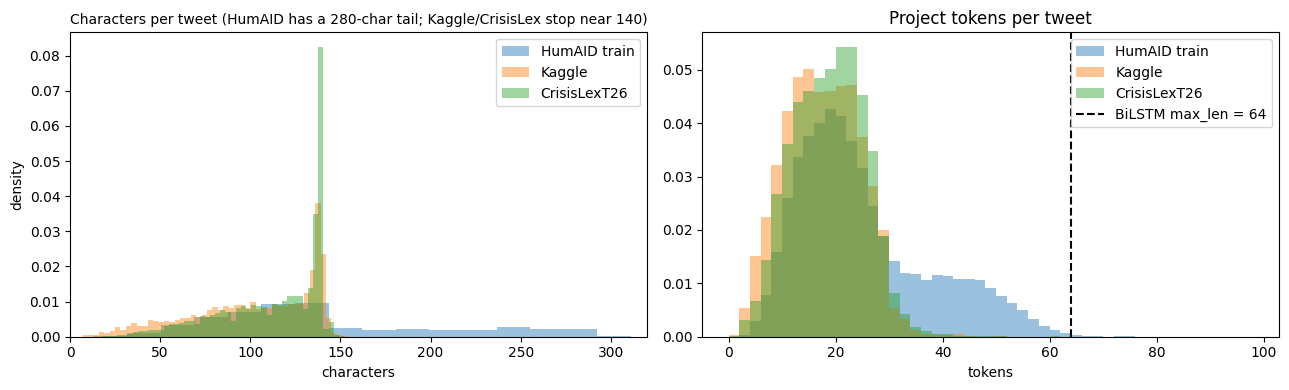

,humaid_train,humaid_validation,humaid_test,kaggle_raw,crisislex
chars p50,125.000,124.000,125.000,107.0,122.000
chars p95,273.000,273.000,273.000,140.0,140.000
chars p99,284.000,285.000,283.000,143.0,144.000
chars max,945.000,475.000,959.000,157.0,152.000
tokens p50,22.000,21.000,22.000,17.0,18.000
tokens p95,50.000,50.000,50.000,28.0,28.000
tokens p99,57.000,57.000,58.000,32.0,33.000
tokens max,120.000,85.000,103.000,50.0,77.000
% tweets over BiLSTM max_len,0.133,0.115,0.191,0.0,0.011


In [4]:
def token_lengths(series):
    return series.fillna("").astype(str).map(clean_tweet_for_tfidf).map(lambda t: len(tokenize_for_vocabulary(t)))

len_sets = {"HumAID train": texts["humaid_train"], "Kaggle": texts["kaggle_raw"], "CrisisLexT26": texts["crisislex"]}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, s in len_sets.items():
    axes[0].hist(s.fillna("").astype(str).str.len(), bins=50, alpha=0.45, density=True, label=name)
    axes[1].hist(token_lengths(s), bins=np.arange(0, 100, 2), alpha=0.45, density=True, label=name)
axes[0].set(title="Characters per tweet (HumAID has a 280-char tail; Kaggle/CrisisLex stop near 140)", xlabel="characters", ylabel="density", xlim=(0, 320))
axes[0].title.set_fontsize(10)
axes[1].set(title="Project tokens per tweet", xlabel="tokens")
axes[1].axvline(BILSTM_MAX_SEQUENCE_LENGTH, color="k", ls="--", label=f"BiLSTM max_len = {BILSTM_MAX_SEQUENCE_LENGTH}")
for a in axes: a.legend()
plt.tight_layout(); plt.savefig(E.EDA_DIR / "length_distributions.png", dpi=110); plt.show()

length_table = pd.DataFrame({n: {**{f"chars {k}": p["char_length"][k] for k in ("p50", "p95", "p99", "max")},
                                 **{f"tokens {k}": p["project_token_length"][k] for k in ("p50", "p95", "p99", "max")},
                                 "% tweets over BiLSTM max_len": p["pct_over_bilstm_max_len"]}
                             for n, p in profiles.items()})
display(length_table)
summary["A8_length_table"] = length_table.to_dict()

## A9 - Vocabulary size and OOV rate
The vocabulary is rebuilt here exactly as `run_sequences.py` builds it (HumAID **train** only, `min_frequency=2`). OOV is the share of tokens of each dataset that fall outside it.

In [5]:
train_clean = texts["humaid_train"].map(clean_tweet_for_tfidf)
vocab = build_vocabulary(train_clean)
cleaned = {n: s.fillna("").astype(str).map(clean_tweet_for_tfidf) for n, s in texts.items()}
oov = {n: oov_stats(c, vocab) for n, c in cleaned.items()}
oov_table = pd.DataFrame(oov).T
oov_table["distinct_token_types"] = [len({t for x in cleaned[n] for t in tokenize_for_vocabulary(x)}) for n in oov_table.index]
display(oov_table)
print("HumAID train vocabulary size (min_frequency=2):", len(vocab))
summary["A9_oov_vs_humaid_train_vocab"] = oov; summary["A9_humaid_vocab_size"] = len(vocab)

,tokens,oov_tokens,oov_rate_pct,distinct_token_types
humaid_train,1327473.0,27169.0,2.05,48752
humaid_validation,192575.0,5915.0,3.07,16446
humaid_test,375943.0,11247.0,2.99,23834
kaggle_raw,130104.0,13559.0,10.42,15072
crisislex,510563.0,99397.0,19.47,36698


HumAID train vocabulary size (min_frequency=2): 21585


## A10 - Language check
**Watch the CrisisLexT26 column** - it is far from English-only (explained in D7).

`langdetect` on a random sample of 3,000 tweets per dataset (letters only, placeholders removed; tweets with fewer than 15 letters are reported as `too_short`).

In [6]:
lang = {n: E.language_profile(texts[n]) for n in ("humaid_train", "kaggle_raw", "crisislex")}
lang_table = pd.DataFrame({n: v["share_pct"] for n, v in lang.items()}).fillna(0).sort_values("humaid_train", ascending=False)
display(lang_table)
summary["A10_language_sample_pct"] = {n: v["share_pct"] for n, v in lang.items()}

,humaid_train,kaggle_raw,crisislex
en,98.27,94.00,71.20
da,0.33,0.00,0.00
es,0.23,0.00,11.10
af,0.23,0.47,0.00
it,0.23,0.40,6.10
pt,0.17,0.00,2.40
too_short,0.00,2.17,0.00
fr,0.00,0.40,2.33
no,0.00,0.40,0.00
tl,0.00,0.00,2.10


## A11-A13 - Hashtags, @mentions, URLs, emoji
`top1_share_pct` / `top10_share_pct` show whether a handful of hashtags dominate (a sign of one viral event skewing a dataset).

In [7]:
tags = pd.DataFrame({n: pd.Series(profiles[n]["hashtags"]["top20"]).head(10).index for n in ("humaid_train", "kaggle_raw", "crisislex")})
display(tags)
shares = pd.DataFrame({n: {"unique hashtags": p["hashtags"]["unique"], "top1 share %": p["hashtags"]["top1_share_pct"],
                           "top10 share %": p["hashtags"]["top10_share_pct"],
                           "mentions / row": p["mentions"]["mean_per_row"], "rows with URL": p["urls"]["rows_with"],
                           "URLs / row": p["urls"]["mean_per_row"], "rows with emoji": p["emoji"]["rows_with"],
                           "unique emoji": p["emoji"]["unique"]} for n, p in profiles.items()})
display(shares)
display(pd.DataFrame({n: pd.Series(profiles[n]["emoji"]["top10"]).head(5) for n in ("humaid_train", "crisislex")}).fillna(""))

,humaid_train,kaggle_raw,crisislex
0,#keralafloods,#news,#terremoto
1,#harvey,#hot,#sardegna
2,#cycloneidai,#prebreak,#rescueph
3,#hurricaneharvey,#best,#bigwet
4,#keralafloodrelief,#nowplaying,#sghaze
5,#earthquake,#islam,#amuay
6,#hurricanedorian,#hiroshima,#bangladesh
7,#hurricanemaria,#earthquake,#earthquake
8,#hurricaneflorence,#gbbo,#nswfires
9,#irma,#jobs,#yycflood


,humaid_train,humaid_validation,humaid_test,kaggle_raw,crisislex
unique hashtags,12814.000,3101.000,5093.000,1917.000,5493.000
top1 share %,4.350,4.230,4.460,2.230,2.650
top10 share %,25.630,24.880,25.620,8.570,21.370
mentions / row,0.619,0.604,0.613,0.353,0.805
rows with URL,4.000,0.000,1.000,3971.000,14339.000
URLs / row,0.000,0.000,0.000,0.620,0.541
rows with emoji,1591.000,217.000,428.000,0.000,519.000
unique emoji,302.000,100.000,142.000,0.000,142.000


,humaid_train,crisislex
☔,,49.0
♥,,40.0
⚠,62.0,
❤,693.0,78.0
➡,85.0,
🏼,61.0,
😔,,102.0
🙏,172.0,157.0


## A14 - Tweet ID uniqueness
HumAID's CSVs contain only `tweet_text` and `class_label` (no ID column) - documented as *not applicable*. Kaggle and CrisisLexT26 have IDs.

In [8]:
id_table = pd.DataFrame({n: profiles[n]["ids"] for n in ("kaggle_raw", "crisislex")})
display(id_table)
print("HumAID: columns =", list(humaid["train"].columns), "-> no ID column (N/A)")
summary["A14_ids"] = id_table.to_dict()

,kaggle_raw,crisislex
unique,7613,27932
duplicate_ids,0,1
ids_with_different_texts,0,0


HumAID: columns = ['tweet_text', 'class_label'] -> no ID column (N/A)


## A15 - Manual reading: 15 random rows (not `.head()`) per dataset
Read these and note anything surprising. (HumAID is read per class in section B.)

In [9]:
display(E.sample_rows(kaggle, "text", n=15, seed=1).rename(columns={"text": "Kaggle - random rows"}))
display(E.sample_rows(crisislex, "Tweet Text", n=15, seed=1).rename(columns={"Tweet Text": "CrisisLexT26 - random rows"}))

,Kaggle - random rows
3228,Goulburn man Henry Van Bilsen missing: Emergency services are searching for a Goulburn man who disappeared...
3706,The things we fear most in organizations--fluctuations disturbances imbalances--are the primary sources of...
6957,@tsunami_esh ?? hey Esh
2887,@POTUS you until you drown by water entering the lungs. You being alive has caused this great country to f...
7464,Crawling in my skin\nThese wounds they will not hea
2539,#np agalloch - the desolation song
6837,Hollywood Movie About Trapped Miners Released in Chile: 'The 33' Hollywood movie about trapped miners star...
7386,New roof and hardy up..Windstorm inspection tomorrow http://t.co/kKeH8qCgc3
1506,The Catastrophic Effects of Hiroshima and Nagasaki Atomic Bombings Still Being Felt Today http://t.co/WC8A...
1875,tiffanyfrizzell has a crush: http://t.co/RaF732vRtt


,CrisisLexT26 - random rows
13244,“@danielpetty: Major air rescue for Boulder County foothills planned for Monday http://t.co/175GGwjkSZ #CO...
14824,@Mtee_CheckItout @JenssXD Really miss our childhood bonding huhuhu.. #Ragnarok #Levelup #Dustpan #HelpHel...
5065,@keancipriano Ust hospital needs help! Their generator wont last long. Patients will suffer. #Rescueph #Re...
7049,"RT @UNoticias: Yo voy para allá, me han dicho que es riesgoso, pero yo voy #ChavezDice #Amuay http://t.co/..."
27140,Praying for the families in the Great State of Texas that were involved in the Fertilizer Plant explosion.
8646,RT @ezralevant: Disgraceful @pembina fundraising e-mail exploits Calgary flood victims. To be clear: they'...
25920,If philippines have Super Typhoon in UFC they have SUPERFIGHT!!! #DOMINICKCRUZVSDEMETRIOUSJOHNSON
13836,“@YourAnonNews: State now tracking 10 oil and gas spills in Colorado flood zones http://t.co/xIAUAOJcfm #C...
419,Hope this rain is making it up to the fire and doing the firefighters some good. #HighParkFire
2124,RT @kaisha: ok... that was NOT cool!!! :( #earthquake


## Re-verification of the cleaning on the rows that triggered each finding
Raw -> cleaned for tweets with HTML entities, encoding damage and chained retweet prefixes (cleaned by the production function).

In [10]:
def show_before_after(series, mask, n=4, seed=0):
    rows = series[mask].sample(min(n, int(mask.sum())), random_state=seed)
    return pd.DataFrame({"raw": rows.str[:90], "cleaned": rows.map(clean_tweet_for_tfidf).str[:90]})

k = kaggle["text"]
print("HTML-entity rows (Kaggle):");     display(show_before_after(k, k.str.contains(E.ENTITY_RE)))
print("Encoding-damage rows (Kaggle):"); display(show_before_after(k, k.str.contains(E.MOJIBAKE_PATTERN)))
h = texts["humaid_train"]
print("Retweet-prefix rows (HumAID):");  display(show_before_after(h, h.str.match(r"^\s*RT\s+@", case=False)))
print("Entities left after cleaning (all five sets):", {n: p["html_entity_rows_after_cleaning"] for n, p in profiles.items()})

HTML-entity rows (Kaggle):


,raw,cleaned
171,Early wake up call from my sister begging me to come over &amp; ride w/her in the ambulanc,early wake up call from my sister begging me to come over & ride w/her in the ambulance to
5074,Hello natural hazards/disaster recovery &amp; emergency management ppl can u recommend goo,hello natural hazards/disaster recovery & emergency management ppl can u recommend good ha
2134,#CDCwhistleblower 2 deaths from measles complications in 10 yrs everyone looses their shit,cdcwhistleblower 2 deaths from measles complications in 10 yrs everyone looses their shit.
4150,I don't pray harm on members of ISIS.I pray they experience the life-rebooting love of God,i don't pray harm on members of isis.i pray they experience the life-rebooting love of god


Encoding-damage rows (Kaggle):


,raw,cleaned
6563,ÛÏ@BBCWomansHour: Setsuko Thurlow survived the #Hiroshima bomb. This is her story: http:/,usertoken : setsuko thurlow survived the hiroshima bomb. this is her story: urltoken urlto
3727,Couples having less sex... for fear it'll be a let down: Internet movies and books saying,couples having less sex... for fear it'll be a let down: internet movies and books saying
128,'Remembering that you are going to die is the best way I know to avoid the trap of thinkin,'remembering that you are going to die is the best way i know to avoid the trap of thinkin
6135,A demoness with the voice of an angel. Like a siren's call beckoning me to the void. Don't,a demoness with the voice of an angel. like a siren's call beckoning me to the void. don't


Retweet-prefix rows (HumAID):


,raw,cleaned
22094,RT @geeknik: The Arecibo Radio Telescope Suffered Significant Hurricane Damage,the arecibo radio telescope suffered significant hurricane damage
4676,RT @WoadKing: Jesus christ there are still decent aftershocks going on #eqnz,jesus christ there are still decent aftershocks going on eqnz
52185,RT @jazengr: So the death toll has risen to 19 and injured are over 300 with large-scale d,so the death toll has risen to 19 and injured are over 300 with large-scale destruction ne
3922,"RT @VeronikaMeduna: Just drove through Wellington, eerily empty, ferries at anchor in harb","just drove through wellington, eerily empty, ferries at anchor in harbour as docks damaged"


Entities left after cleaning (all five sets): {'humaid_train': 0, 'humaid_validation': 0, 'humaid_test': 0, 'kaggle_raw': 0, 'crisislex': 0}


---
# SECTION B - HumAID-specific checks
HumAID trains the primary classifier, so these checks concern label quality and split integrity.

## B1, B2, B4, B6 - Class distribution, imbalance, consistency across splits, rare classes

count                  percent                  
                                        train validation  test   train validation   test
class_label                                                                             
rescue_volunteering_or_donation_effort  14891       2168  4219   27.82      27.82  27.83
other_relevant_information               8501       1236  2407   15.88      15.86  15.88
sympathy_and_support                     6250        909  1772   11.68      11.66  11.69
infrastructure_and_utility_damage        5715        831  1617   10.68      10.66  10.67
injured_or_dead_people                   5110        746  1447    9.55       9.57   9.54
not_humanitarian                         4407        644  1245    8.23       8.26   8.21
caution_and_advice                       3774        550  1070    7.05       7.06   7.06
displaced_people_and_evacuations         2800        409   790    5.23       5.25   5.21
requests_or_urgent_needs                 1833        264   521    3.42       3.39   3.44
missing_or_found_people                   250         36    72    0.47       0.46   0.47

imbalance ratio (train, largest/smallest class): 59.6
classes with fewer than 500 training rows: ['missing_or_found_people']
largest class-share gap train vs validation: 0.03 pp | train vs test: 0.02 pp


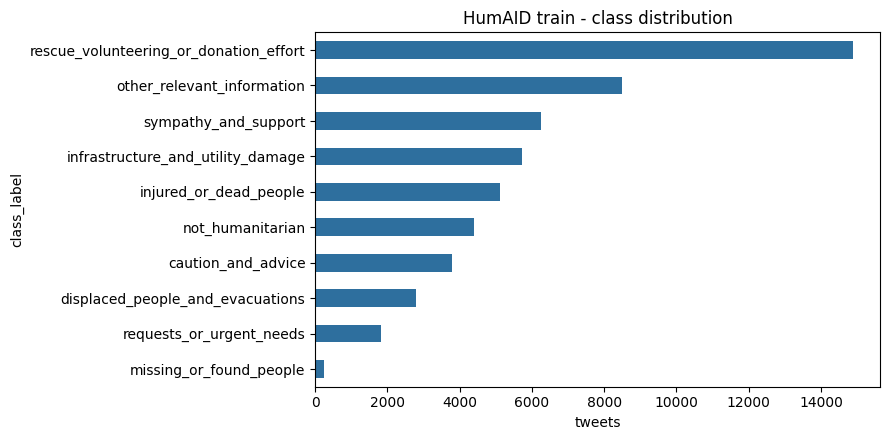

In [11]:
dist = E.class_distribution(humaid)
pct = (dist / dist.sum() * 100).round(2)
display(pd.concat({"count": dist, "percent": pct}, axis=1))

imbalance = dist["train"].max() / dist["train"].min()
rare = dist.index[dist["train"] < 500].tolist()
gap_val = float((pct["train"] - pct["validation"]).abs().max())
gap_test = float((pct["train"] - pct["test"]).abs().max())
print(f"imbalance ratio (train, largest/smallest class): {imbalance:.1f}")
print(f"classes with fewer than 500 training rows: {rare}")
print(f"largest class-share gap train vs validation: {gap_val:.2f} pp | train vs test: {gap_test:.2f} pp")

fig, ax = plt.subplots(figsize=(9, 4.5))
dist["train"].sort_values().plot.barh(ax=ax, color="#2E6F9E")
ax.set(title="HumAID train - class distribution", xlabel="tweets")
plt.tight_layout(); plt.savefig(E.EDA_DIR / "humaid_class_distribution.png", dpi=110); plt.show()
summary["B_class_distribution"] = {"counts": dist.to_dict(), "imbalance_ratio": round(float(imbalance), 1),
                                   "classes_under_500_train": rare, "max_gap_train_val_pp": gap_val, "max_gap_train_test_pp": gap_test}

## Label set vs the public dataset card (and B7)
The public card lists 11 labels; the supplied files contain 10. `dont_know_cant_judge` never occurs, so **B7 (compare `dont_know_cant_judge` with `not_humanitarian`) is not applicable**. The nearest genuinely ambiguous pair - `not_humanitarian` vs `other_relevant_information` - is read instead, below.

In [12]:
schema = describe_label_schema(humaid["train"]["class_label"])
print(json.dumps(schema, indent=2))
all_splits_same = all(set(d["class_label"]) == set(humaid["train"]["class_label"]) for d in humaid.values())
print("same classes in all three splits:", all_splits_same)
summary["B_label_schema"] = schema

tr = humaid["train"]
for lab in ("not_humanitarian", "other_relevant_information"):
    print("\n##", lab); display(tr[tr.class_label == lab].sample(10, random_state=3)[["tweet_text"]])

{
  "num_classes_present": 10,
  "classes_present": [
    "caution_and_advice",
    "displaced_people_and_evacuations",
    "infrastructure_and_utility_damage",
    "injured_or_dead_people",
    "missing_or_found_people",
    "not_humanitarian",
    "other_relevant_information",
    "requests_or_urgent_needs",
    "rescue_volunteering_or_donation_effort",
    "sympathy_and_support"
  ],
  "card_labels_absent_from_data": [
    "dont_know_cant_judge"
  ],
  "labels_not_on_card": []
}
same classes in all three splits: True

## not_humanitarian


,tweet_text
5922,"RT @JTMiller7423: Whatever you do, DO NOT donate to the Clinton Haiti hurricane relief fund. It is a scam!..."
33557,"4:53 AM Eastern Friday Morning September 14,2018 My vehicle is now Parked at my Workplace @ Hampton Roads ..."
26123,@InezFeltscher @SebGorka Our last Governor of Maryland (OMalley) taxed our rain water. You couldnt harvest...
36724,"Lets be real, I prepared for the health of my dog better than I have for me for #HurricaneFlorence. Im goi..."
1204,RT @ScottTalking: Mon ST Show! @AM900CHML- Premier will tour Fort McMurray to survey damage. How will resi...
39088,"@Owind1950 @Alyssa_Milano this infuriates me, that @Alyssa_Milano shows no care or support for the victims..."
29018,#Kerala HC dismisses Writ Petititon; says acceptance of help from another country is a matter of foreign p...
17284,"After Irma, you may be able to get mortgage payments deferred, in some cases, up to a year. Deferrals are ..."
41764,California Wild Fires; Far From Normal via @YouTube
40881,3am and hes bashing Americans who are currently battling a forest fire that killed people. There is no bot...



## other_relevant_information


,tweet_text
40929,The #CampFire is part of the deadliest wildfire outbreak in modern American history. It’s our choice wheth...
15279,"@Salon After hurricane Harvey, Irma, floods in India Nepal, Bangladesh. I wonder what changed their minds?"
28510,"Hindu Mahasabha’s official website hacked, displays recipe for ‘beef curry’ - #Kerala #HinduMahasabha #Flo..."
21983,"RT @WeRAllDivine: Ὢ8Mayor #CarmenYulinCruz is orchestrating PR ppls Genocide.Withholding food, water &amp;..."
22852,RT @PaulHBeckwith: Next to be affected along the path of #HurricaneMaria is the #DominicanRepublic &amp; t...
27863,This is Kerala Education Minister C Raveendranath carrying relief material on his shoulders. Happens only ...
30468,RT @airnewsalerts: Listen to Spotlight: Discussion on Prime Minister’s visit to Flood Affected areas in #K...
27801,Sometimes all it takes is a bit of awareness and precautions! Could the Kerala Floods be predicted? Read o...
12667,#TexasStrong #Harveys Houston from above: Aerial photos show extreme flooding in Bayou City via Houston B...
6835,We have already served hundreds of families affected by #HurricaneHarvey at our distribution site in Victo...


## B3 - Event vs label
The CSVs carry **no event column**, so a true event cross-tab is impossible from the repository data. As a *proxy*, tweets are bucketed by disaster **type** keywords (earthquake / hurricane-storm / flood / wildfire). This is a rough keyword assignment, not event metadata. If the per-event files from the QCRI release are added later, replace this cell with a real event x label table and re-run the leakage audit by event.

In [13]:
tr = humaid["train"].copy()
tr["disaster_type_proxy"] = E.disaster_type_proxy(tr)
print("share of train tweets per disaster-type proxy (%):")
display(tr["disaster_type_proxy"].value_counts(normalize=True).mul(100).round(1).to_frame("percent"))
print("class mix within each proxy type (column %):")
display((pd.crosstab(tr["class_label"], tr["disaster_type_proxy"], normalize="columns") * 100).round(1))
summary["B3_event_metadata_available"] = False

share of train tweets per disaster-type proxy (%):


,percent
disaster_type_proxy,
hurricane/storm,46.3
flood,15.1
unknown,14.9
wildfire,13.5
earthquake,10.3


class mix within each proxy type (column %):


disaster_type_proxy,earthquake,flood,hurricane/storm,unknown,wildfire
class_label,,,,,
caution_and_advice,5.7,6.4,9.1,6.5,2.4
displaced_people_and_evacuations,0.3,0.9,7.4,5.5,6.2
infrastructure_and_utility_damage,7.4,5.8,15.0,8.2,6.5
injured_or_dead_people,19.5,4.6,7.0,3.9,22.3
missing_or_found_people,0.0,1.1,0.1,0.1,1.8
not_humanitarian,5.0,5.9,4.3,20.9,12.7
other_relevant_information,10.2,15.5,18.3,14.3,14.0
requests_or_urgent_needs,2.1,5.3,3.1,5.8,1.0
rescue_volunteering_or_donation_effort,22.5,45.4,26.6,20.5,24.6


## B5 - Duplicates / near-duplicates leaking across train / validation / test

In [14]:
pairs = [("train", "validation"), ("train", "test"), ("validation", "test")]
leak = pd.DataFrame({f"{a} -> {b}": overlap(humaid[a]["tweet_text"], humaid[b]["tweet_text"]) for a, b in pairs}).T
display(leak)
summary["B5_split_overlap"] = leak.to_dict("index")

shared = set(humaid["train"]["tweet_text"].str.strip()) & set(humaid["validation"]["tweet_text"].str.strip())
print(f"\n{len(shared)} exact texts appear in BOTH train and validation (official splits are left untouched; disclosed in docs):")
for t in sorted(shared): print("  -", t[:110])

,exact_shared_texts,near_shared_texts,rows_in_second_with_near_twin,second_rows,pct_of_second
train -> validation,4.0,5.0,5.0,7793.0,0.06
train -> test,0.0,0.0,0.0,15160.0,0.00
validation -> test,0.0,0.0,0.0,15160.0,0.00



4 exact texts appear in BOTH train and validation (official splits are left untouched; disclosed in docs):
  - Keep these in your prayers tonight: - Earthquake in Mexico - Flooding in India - Hurricane Maria in Caribbean 
  - Lady Gaga will be donating $1M to relief efforts for Hurricane Harvey, Irma, José, Maria, and the Mexico City 
  - RT @MerrellTwins: Our thoughts &amp; prayers are with those affected by the earthquake in Mexico &amp; Hurrica
  - RT @landovela1: Pray for Mexico they just had another earthquake. Pray for Puerto Rico &amp; the islands that 


## B-manual - 15 random tweets per class
Read every block. Pay attention to the confusable classes (`other_relevant_information`, `not_humanitarian`, `sympathy_and_support`).

In [15]:
manual = E.sample_rows(humaid["train"], "tweet_text", n=15, seed=7, by="class_label")
for lab, g in manual.groupby("class_label"):
    print(f"\n##### {lab}"); display(g[["tweet_text"]].reset_index(drop=True))


##### caution_and_advice


,tweet_text
0,"Both Carolinas and Virginia have declared states of emergency ahead of Hurricane Florence, which is expect..."
1,"This section of I-10 east is completely under water, even our high water vehicle cant cross. Avoid this pa..."
2,Hurricane dorian catagory 5 hurticane Winds in excess of 175 mph gust upto 200 mph abaco islands of the ba...
3,Aug 31 5 PM Update: Tropical Storm Watches have been issued for Treasure Coast. Based on the current track...
4,Sullivan’s Island is alerting visitors and residents that present ocean conditions are extremely dangerous...
5,It is important to have clean water during an emergency. Store at least 1 gallon of water per day for each...
6,ALBERTA WILDFIRES | ALERT! Regional Municipality of Wood Buffalo.
7,"At 3:44 PM EDT, 1 W Busick [Yancey Co, NC] EMERGENCY MNGR reports FLASH FLOOD. NUMEROUS ROADS CLOSED ACROS..."
8,"@SkyNewsBreak @BBCBreaking @BBCWorld @SkyNews @ReutersWorld Florida hurricane Irma warnings, evacuations u..."
9,@NOAA NHC 8AM EDT 092517 MARIA 30.8N 73.0W Cat 1-75 mph N 7mph 961mb Tropical Storm WARNING: NC Coast Extr...



##### displaced_people_and_evacuations


,tweet_text
0,RT @WFMY: Winston-Salem apartments evacuated as flood waters creep in
1,RT @Re2pect95: Dorian: *heads to Florida* Florida: Emergency evacuation Dorian: Actually ima hit GA &amp; ...
2,"RT @CBCAlerts: Fires near #FortStJohn, B.C., prompt evacuation orders, CBCs @KamilKaramali reports:"
3,Evacuation Airlift. @USNavy #sailor prepares victims inside a #MH60 Ὠ1 for evacuation from #Dominica follo...
4,Camp Fire Evacuation Update - Oroville 11.10.18 #campfire @ButteSheriff @paradise_ca @CHP_Valley @Countyof...
5,BREAKING: Mandatory evacuations ordered - #ClipTrends #VideoTrends #News_Po #Hurricane_Harvey #New_Jersey...
6,BREAKING: The main levee in Brazoria County just broke EVACUATE NOW! #HoustonStrong #HurricaneHarvey #Harv...
7,Thinking this morning of the health professionals managing evacuation of hospitals and nursing homes. Thes...
8,Always fun to watch the Eagle evacuation ✈️
9,The CRA is committed to assisting #wildfire evacuees with taxpayer relief #ymm



##### infrastructure_and_utility_damage


...

,tweet_text
0,I got this 4m my friend someone. Plz help #hurricaneharvey #houstonflooding #harvey #Harvey2017 #HarveySto...
1,PLEASE RT THE TWEET BELOW TO HELP US OUT: @FACACoach @FHS7v7A @FHSAA @scorestream @FDPlayBook @FOXSportsFL...
2,"Need help to arrange a vehicle from trivandrum to ranni , Medical and Sanitary items , Doctors are waiting..."
3,"Help meet the humanitarian needs emerging after #CycloneIdai struck Mozambique, causing tremendous devasta..."
4,"Over 8,500 #txst students live in areas impacted by Hurricane Harvey, and they need your help."
5,"@realDonaldTrump get puerto rico help, power, food, and resources !!!!!"
6,"@realDonaldTrump We have fight in every war, and our blood have been drained. We need help now!!! #PuertoR..."
7,We need fosters! Can you foster sweet Droopy? He needs out of his rural WV shelter location so he can find...
8,@aspca @bestfriends @HumaneSociety if youre in fl can you please help my friends please #freespiritrescue ...
9,Please pray for the victims of recent earthquake in AJK. #earthquake On 24th Sep an earthquake of 5.8 magn...



##### rescue_volunteering_or_donation_effort


,tweet_text
0,RT @jmckay1979: Olympic medallists flip burgers in support of Fort McMurray wildfire victims
1,Focusing on rescue activities in quake-hit areas: NDMA Chairman. #pakistan
2,RT @bbb_give: Hurricane Matthew devastates Haiti and heads for the U.S. coast. BBB WGA offers tips on how ...
3,"These 6 MNPD members are leaving now for Tallahassee, FL to be in place to help Floridians after Hurricane..."
4,RT @FieldGuideInc: Check out El Fondo Boricua (A Fund of St. Paul Foundation) Hurricane Maria Relief Fundr...
5,#HurricaneIrmas Smallest Victims Receive Life-Saving Medical Treatment After Storm: Huffington Post #envi...
6,Or another one of the Texas-based food banks listed here:
7,We all have a chance to respond as fellow citizens to help one another &amp; show our best side #HoustonFl...
8,This is coming up! Get your tickets for MAY 21st- proceeds go to @RedCrossAB for wildfire relief #supportt...
9,Our hearts go out to Puerto Rico and the family of @ToroArnaldo ἟5἟7 Donate to Hurricane Maria efforts here:



##### sympathy_and_support


,tweet_text
0,on my knees just praying for my Caribbean people this morning!! My heart goes out to you in a time like th...
1,Peter Miguel Camejo ¡Presente!: As we wrestle in 2018 with the California wildfires on top of all other Es...
2,We convey our deepest condolences over the loss of lives during wildfires in #Greece. Our thoughts are wit...
3,Hurricane Maria has devastated the Atlantic. Please keep all of those who have been affected by this storm...
4,RT @Ulkoministerio: Our deepest condolences to our long-term partner country #Mozambique and the families ...
5,@k0okiesgirl Please pray for us.. A lot of my friends and relatives are suffering ryt now.. My area is not...
6,"My thoughts across New Zealand, for those suffering loss from the #earthquake #nzearthquake , please be sa..."
7,Hope everyone is ok after the earthquake that was felt across New Zealand.
8,I can’t stop crying! Seeing this devastation from these fires and knowing I have dear friends who have los...
9,@MelissaPonzio1 can you send a prayer for Italian victims ? ὡ4἞E἟9 #earthquake #PrayForItaly


---
# SECTION C - Kaggle "NLP with Disaster Tweets" checks
This dataset trains the binary pre-filter. The raw file is analysed **as shipped** - nothing is deduplicated or overwritten here (the pipeline does that in `run_kaggle_preprocessing.py`).

## C1 - Target balance

,rows,percent
0 = not disaster,4342,57.0
1 = disaster,3271,43.0


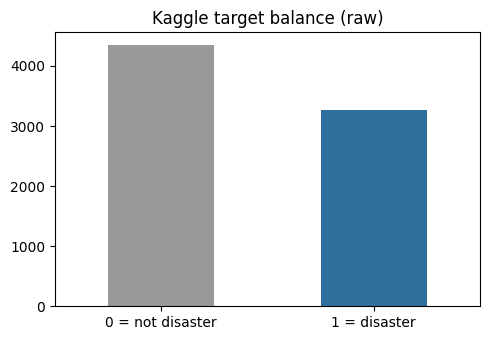

In [16]:
bal = kaggle["target"].value_counts().sort_index().to_frame("rows").assign(percent=lambda d: (d.rows / d.rows.sum() * 100).round(1))
bal.index = ["0 = not disaster", "1 = disaster"]
display(bal)
fig, ax = plt.subplots(figsize=(5, 3.5)); bal["rows"].plot.bar(ax=ax, color=["#999", "#2E6F9E"], rot=0)
ax.set(title="Kaggle target balance (raw)"); plt.tight_layout(); plt.savefig(E.EDA_DIR / "kaggle_target_balance.png", dpi=110); plt.show()
summary["C1_target_balance_raw"] = bal.to_dict("index")

## C2 - `keyword` column: coverage and shortcut risk
A keyword that is 100% one class would let a model skip the tweet text entirely.

In [17]:
kw = kaggle.dropna(subset=["keyword"])
g = kw.groupby("keyword")["target"].agg(disaster_rate="mean", rows="count")
pure = g[(g.rows >= 10) & g.disaster_rate.isin([0.0, 1.0])]
print(f"missing keyword: {kaggle.keyword.isna().mean()*100:.1f}% | unique keywords: {kaggle.keyword.nunique()} | "
      f"keywords (>=10 rows) that are 100% one class: {len(pure)}")
print("\nmost disaster-associated keywords:"); display(g[g.rows >= 10].sort_values("disaster_rate", ascending=False).head(6))
print("least disaster-associated keywords:"); display(g[g.rows >= 10].sort_values("disaster_rate").head(6))
spread = g[g.rows >= 10].disaster_rate
print(f"share of keywords with a disaster rate below 10% or above 90%: {((spread < .1) | (spread > .9)).mean()*100:.1f}%")
summary["C2_keyword"] = {"missing_pct": round(float(kaggle.keyword.isna().mean() * 100), 1), "unique": int(kaggle.keyword.nunique()),
                         "pure_keywords_ge10_rows": int(len(pure)),
                         "pct_keywords_extreme_rate": round(float(((spread < .1) | (spread > .9)).mean() * 100), 1)}

missing keyword: 0.8% | unique keywords: 221 | keywords (>=10 rows) that are 100% one class: 4

most disaster-associated keywords:


,disaster_rate,rows
keyword,,
debris,1.000000,37
derailment,1.000000,39
wreckage,1.000000,39
outbreak,0.975000,40
oil%20spill,0.973684,38
typhoon,0.973684,38


least disaster-associated keywords:


,disaster_rate,rows
keyword,,
aftershock,0.000000,34
body%20bags,0.024390,41
ruin,0.027027,37
blazing,0.029412,34
body%20bag,0.030303,33
electrocute,0.031250,32


share of keywords with a disaster rate below 10% or above 90%: 15.0%


## C3 - `location` column: how usable is it?

In [18]:
loc = kaggle["location"].dropna()
once = (loc.value_counts() == 1).sum() / loc.nunique()
print(f"missing: {kaggle.location.isna().mean()*100:.1f}% | distinct values: {loc.nunique()} ({loc.nunique()/len(loc)*100:.0f}% of non-null rows) | "
      f"values that occur exactly once: {once*100:.0f}%")
display(loc.value_counts().head(10).to_frame("rows"))
display(loc.sample(15, random_state=2).to_frame("random non-null locations"))
summary["C3_location"] = {"missing_pct": round(float(kaggle.location.isna().mean() * 100), 1), "distinct": int(loc.nunique()),
                          "pct_values_occurring_once": round(float(once * 100), 1)}

missing: 33.3% | distinct values: 3341 (66% of non-null rows) | values that occur exactly once: 84%


,rows
location,
USA,104
New York,71
United States,50
London,45
Canada,29
Nigeria,28
UK,27
"Los Angeles, CA",26
India,24


,random non-null locations
6720,"Asheville, NC"
6335,Stateless Global Citizen
1877,honeymoon avenue
1228,"Washington, D.C."
5294,United States
4882,"Ashburn, VA"
5834,"Portland, OR"
3294,17-Feb
1722,bk.
2049,Instagram: trillrebel_


## C4 - Hard negatives: `target=0` tweets that contain disaster words
Exactly the pattern the pre-filter must learn (figurative "fire", "crash", "storm"...). Read these.

In [19]:
hard = kaggle[(kaggle.target == 0) & kaggle.text.str.contains(r"\b(?:fire|explosion|crash|flood|storm|bomb|burn|collapse|wreck)", case=False)]
print(f"{len(hard)} of {int((kaggle.target == 0).sum())} non-disaster tweets contain a disaster keyword")
display(hard.sample(15, random_state=4)[["text"]])
summary["C4_hard_negatives"] = int(len(hard))

485 of 4342 non-disaster tweets contain a disaster keyword


,text
3756,Fire Meet Gasoline always gotta get played twice lol
1232,Fire hazard associated with installation of non-compliant external cladding on http://t.co/4I0Kz2aKly - By...
1283,I just remembered the McDonald's that burned down used to have the coolest play ground &amp; the new one a...
1271,Always look for the silver lining! \n\nMy barn having burned to the ground\nI can now see the moon.\n~ Mi...
678,Bright &amp; BLAZING Fireman Birthday Party http://t.co/9rFo9GY3nE #Weddings
1322,Why put out a fire that's still burning?
1246,A change in the State fire code prohibits grills on decks at condos and apartment buildings. Check with y...
1636,Catching up on GBBO and omg that girls cake that just totally collapsed I feel so bad
3740,Save the Date! Saturday August 15 2015 is the Salisbury Fire Department Open House at 325 Cypress St 10am ...
1210,@joshcorman #infosec rather you knew it or not your a firefighter now days you often run into burning ...


## C5 - Only the labeled training file is used

In [20]:
test_file = E.RAW / "nlpgettingstarted_test"
test_cols = list(pd.read_csv(test_file, nrows=1).columns) if test_file.exists() else []
print("labeled file columns:", list(kaggle.columns))
print("unlabeled competition file columns:", test_cols, "-> has target:", "target" in test_cols)
print("run_kaggle_preprocessing.py reads only 'nlpgettingstarted_train' (checked automatically by verify_pipeline C7).")
summary["C5_unlabeled_file_has_target"] = "target" in test_cols

labeled file columns: ['id', 'keyword', 'location', 'text', 'target']
unlabeled competition file columns: ['id', 'keyword', 'location', 'text'] -> has target: False
run_kaggle_preprocessing.py reads only 'nlpgettingstarted_train' (checked automatically by verify_pipeline C7).


## C6 - Tweet length by target (shortcut risk)

In [21]:
by_target = pd.DataFrame({"chars": kaggle["text"].str.len(), "tokens": token_lengths(kaggle["text"]), "target": kaggle["target"]})
display(by_target.groupby("target").describe(percentiles=[.5, .95]).T.round(1))
summary["C6_length_by_target_mean"] = by_target.groupby("target")[["chars", "tokens"]].mean().round(1).to_dict()

target             0       1
chars  count  4342.0  3271.0
       mean     95.7   108.1
       std      35.9    29.3
       min       7.0    14.0
       50%     101.0   115.0
       95%     139.0   140.0
       max     157.0   151.0
tokens count  4342.0  3271.0
       mean     16.7    17.7
       std       7.2     6.5
       min       1.0     2.0
       50%      16.0    18.0
       95%      28.0    28.0
       max      50.0    44.0

## Kaggle data quality that drives the pipeline: duplicates, conflicting labels, encoding damage, and what the *old* split leaked

In [22]:
from sklearn.model_selection import train_test_split
k = kaggle[["text", "target"]].copy(); k["key"] = k.text.map(normalize_for_dedup)
n_labels = k.groupby("key")["target"].transform("nunique")
quality = {"rows_raw": len(k), "exact_duplicate_rows": int(k.text.duplicated().sum()),
           "near_duplicate_rows": int(k.key.duplicated().sum()),
           "conflicting_label_groups": int(k[n_labels > 1].key.nunique()), "conflicting_label_rows": int((n_labels > 1).sum()),
           "rows_after_pipeline_dedup": int(len(k[n_labels == 1].drop_duplicates("key"))),
           "rows_with_encoding_damage": int(k.text.str.contains(E.MOJIBAKE_PATTERN).sum())}

# What a naive 80/10/10 split (no deduplication) would have leaked:
tr_, tmp = train_test_split(k, test_size=0.2, random_state=42, stratify=k.target)
va_, te_ = train_test_split(tmp, test_size=0.5, random_state=42, stratify=tmp.target)
quality["naive_split_val_rows_with_twin_in_train"] = int(va_.key.isin(set(tr_.key)).sum())
quality["naive_split_test_rows_with_twin_in_train"] = int(te_.key.isin(set(tr_.key)).sum())
display(pd.Series(quality, name="count").to_frame())
summary["C_quality"] = quality

print("\nExample of conflicting labels (same normalised text, different target):")
display(k[n_labels > 1].sort_values("key").head(8)[["text", "target"]])

,count
rows_raw,7613
exact_duplicate_rows,110
near_duplicate_rows,777
conflicting_label_groups,83
conflicting_label_rows,306
rows_after_pipeline_dedup,6753
rows_with_encoding_damage,669
naive_split_val_rows_with_twin_in_train,111
naive_split_test_rows_with_twin_in_train,112



Example of conflicting labels (same normalised text, different target):


,text,target
3930,2pcs 18W CREE Led Work Light Offroad Lamp Car Truck Boat Mining 4WD FLOOD BEAM - Full reaÛ_ http://t.co/...,0
3917,2pcs 18W CREE Led Work Light Offroad Lamp Car Truck Boat Mining 4WD FLOOD BEAM - Full reaÛ_ http://t.co/...,0
3933,2pcs 18W CREE Led Work Light Offroad Lamp Car Truck Boat Mining 4WD FLOOD BEAM - Full reaÛ_ http://t.co/...,0
3924,2pcs 18W CREE Led Work Light Offroad Lamp Car Truck Boat Mining 4WD FLOOD BEAM - Full reaÛ_ http://t.co/...,1
5817,#360WiseNews : China's Stock Market Crash: Are There Gems In The Rubble? http://t.co/eaTFro3d5x,0
5833,#360WiseNews : China's Stock Market Crash: Are There Gems In The Rubble? http://t.co/aOd2ftBMGU,1
5823,#360WiseNews : China's Stock Market Crash: Are There Gems In The Rubble? http://t.co/9Naw3QOQOL,1
5837,#360WiseNews : China's Stock Market Crash: Are There Gems In The Rubble? http://t.co/gQskwqZuUl,0


---
# SECTION D - CrisisLexT26 checks (external evaluation set - never trained on)

## D1 - Schema consistency across the 26 event files

In [23]:
sch = pd.DataFrame(cl_schemas).T
sch["columns"] = sch["columns"].astype(str)
print("distinct column layouts across the 26 files:", sch["columns"].nunique())
print("files whose header had stray whitespace (stripped before concat):", int(sch["header_had_extra_whitespace"].sum()))
display(sch[["rows", "header_had_extra_whitespace"]])
summary["D1_distinct_schemas"] = int(sch["columns"].nunique())

distinct column layouts across the 26 files: 1
files whose header had stray whitespace (stripped before concat): 26


,rows,header_had_extra_whitespace
2012_Colorado_wildfires,1200,True
2012_Costa_Rica_earthquake,1412,True
2012_Guatemala_earthquake,1050,True
2012_Italy_earthquakes,1000,True
2012_Philipinnes_floods,1000,True
2012_Typhoon_Pablo,1000,True
2012_Venezuela_refinery,1000,True
2013_Alberta_floods,1000,True
2013_Australia_bushfire,1199,True
2013_Bohol_earthquake,1000,True


## D2 - Is the full tweet text included (no rehydration needed)?

In [24]:
txt = crisislex["Tweet Text"]
print(f"non-null text: {txt.notna().mean()*100:.1f}% | median length: {int(txt.str.len().median())} chars | tweet IDs present: {crisislex['Tweet ID'].notna().all()}")
display(txt.sample(5, random_state=5).to_frame("sample text"))
print("-> full text is shipped with every labeled row; no API rehydration is required.")
summary["D2_text_present_pct"] = round(float(txt.notna().mean() * 100), 1)

non-null text: 100.0% | median length: 122 chars | tweet IDs present: True


,sample text
5436,"RT @MgaKasabihan: Snow in Africa, Drought in America, Massive Floods in Manila, Century Volcanic Eruption ..."
3890,Un terremoto en Italia dejó al menos seis muertos!! http://t.co/2FLqUtvZ
13238,Welcome to Boulderlandia. Climb to safety. #boulderflood http://t.co/0PHYmDPSUX
20784,RT @AlterEnergyNews: Nearly 1000 injured as meteor falls in Russia http://t.co/f4UAwMm5
1151,Colorado's most destructive fire nears containment [http://t.co/OoPH3BCu] http://t.co/Z1amfqB7


-> full text is shipped with every labeled row; no API rehydration is required.


## D3 - The three label dimensions, separately

In [25]:
for col in ["Informativeness", "Information Type", "Information Source"]:
    vc = crisislex[col].astype(str).str.strip().value_counts(dropna=False)
    print(f"\n=== {col} ==="); display(pd.DataFrame({"rows": vc, "percent": (vc / vc.sum() * 100).round(1)}))
print("\nInformativeness x Information Type"); 
display(pd.crosstab(crisislex["Informativeness"].astype(str).str.strip(), crisislex["Information Type"].astype(str).str.strip()))
summary["D3_label_dims"] = {c: crisislex[c].astype(str).str.strip().value_counts().to_dict() for c in ["Informativeness", "Information Type", "Information Source"]}


=== Informativeness ===


,rows,percent
Informativeness,,
Related and informative,16849,60.3
Related - but not informative,7732,27.7
Not related,2863,10.2
Not applicable,489,1.8



=== Information Type ===


,rows,percent
Information Type,,
Other Useful Information,7627,27.3
Affected individuals,4790,17.1
Sympathy and support,4650,16.6
Not labeled,3419,12.2
Donations and volunteering,2404,8.6
Caution and advice,2306,8.3
Infrastructure and utilities,1599,5.7
Not applicable,1138,4.1



=== Information Source ===


,rows,percent
Information Source,,
Media,10157,36.4
Outsiders,9252,33.1
Not labeled,3344,12.0
Eyewitness,2193,7.9
Government,1174,4.2
NGOs,982,3.5
Business,419,1.5
Not applicable,412,1.5



Informativeness x Information Type


Information Type,Affected individuals,Caution and advice,Donations and volunteering,Infrastructure and utilities,Not applicable,Not labeled,Other Useful Information,Sympathy and support
Informativeness,,,,,,,,
Not applicable,0,0,0,0,1,488,0,0
Not related,0,0,0,3,1,2856,3,0
Related - but not informative,324,125,338,137,807,31,2020,3950
Related and informative,4466,2181,2066,1459,329,44,5604,700


## D4 - Distribution of the 26 events (does one event dominate?)

,rows,percent
event_name,,
2013_Russia_meteor,1442,5.16
2012_Costa_Rica_earthquake,1412,5.05
2013_Savar_building_collapse,1250,4.47
2013_Queensland_floods,1200,4.30
2012_Colorado_wildfires,1200,4.30
2013_Australia_bushfire,1199,4.29
2013_Glasgow_helicopter_crash,1100,3.94
2012_Guatemala_earthquake,1050,3.76
2013_Typhoon_Yolanda,1048,3.75


events: 26 | smallest: 1000 | largest: 1442 (5.2% of all rows)


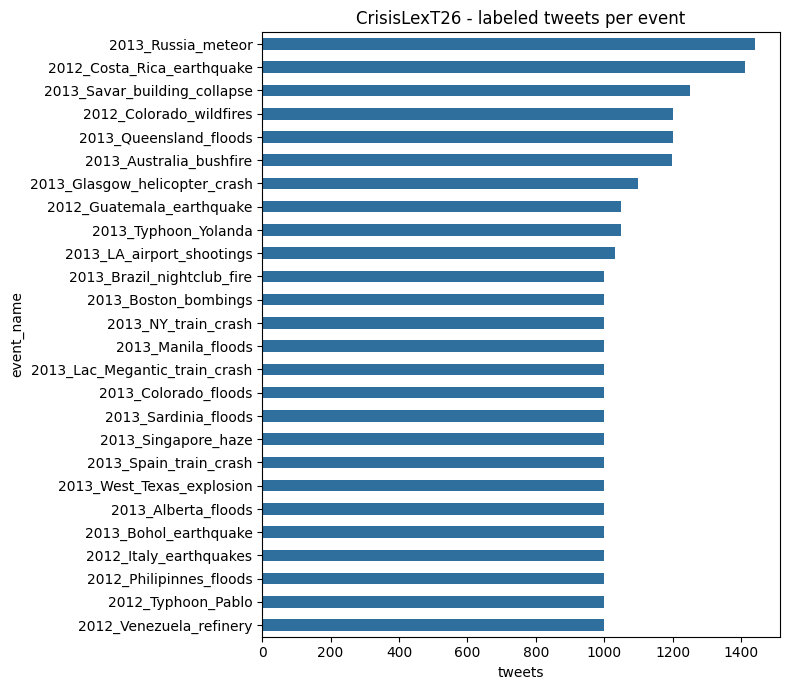

In [26]:
ev = crisislex["event_name"].value_counts()
display(pd.DataFrame({"rows": ev, "percent": (ev / ev.sum() * 100).round(2)}))
print(f"events: {ev.size} | smallest: {ev.min()} | largest: {ev.max()} ({ev.max()/ev.sum()*100:.1f}% of all rows)")
fig, ax = plt.subplots(figsize=(8, 7)); ev.sort_values().plot.barh(ax=ax, color="#2E6F9E")
ax.set(title="CrisisLexT26 - labeled tweets per event", xlabel="tweets"); plt.tight_layout()
plt.savefig(E.EDA_DIR / "crisislex_events.png", dpi=110); plt.show()
summary["D4_events"] = {"events": int(ev.size), "min": int(ev.min()), "max": int(ev.max()), "largest_share_pct": round(float(ev.max() / ev.sum() * 100), 1)}

## D5 - Era-specific vocabulary (2012-13 vs HumAID 2016-19)
This quantifies the distribution shift the robustness test will measure.

In [27]:
def top_tokens(series, n=5000):
    from collections import Counter
    c = Counter(t for x in series.fillna("").astype(str).map(clean_tweet_for_tfidf) for t in tokenize_for_vocabulary(x))
    return {w for w, _ in c.most_common(n)}

a, b = top_tokens(texts["humaid_train"]), top_tokens(texts["crisislex"])
jacc = len(a & b) / len(a | b)
ha = set(profiles["humaid_train"]["hashtags"]["top20"]); hb = set(profiles["crisislex"]["hashtags"]["top20"])
print(f"Jaccard overlap of the 5,000 most frequent tokens: {jacc:.2f}")
print(f"top-20 hashtags shared by both datasets: {sorted(ha & hb)}")
display(pd.DataFrame({"HumAID 2016-19 top hashtags": list(profiles['humaid_train']['hashtags']['top20'])[:12],
                      "CrisisLexT26 2012-13 top hashtags": list(profiles['crisislex']['hashtags']['top20'])[:12]}))
summary["D5_era_shift"] = {"top5000_token_jaccard": round(jacc, 3), "shared_top20_hashtags": sorted(ha & hb)}

Jaccard overlap of the 5,000 most frequent tokens: 0.35
top-20 hashtags shared by both datasets: ['#earthquake']


,HumAID 2016-19 top hashtags,CrisisLexT26 2012-13 top hashtags
0,#keralafloods,#terremoto
1,#harvey,#sardegna
2,#cycloneidai,#rescueph
3,#hurricaneharvey,#bigwet
4,#keralafloodrelief,#sghaze
5,#earthquake,#amuay
6,#hurricanedorian,#bangladesh
7,#hurricanemaria,#earthquake
8,#hurricaneflorence,#nswfires
9,#irma,#yycflood


## D6 - `event_name` is retained
`event_name` comes from each file's folder name and stays a column all the way through `run_crisislex_preprocessing.py` (verified by `verify_pipeline` D6).

In [28]:
print("event_name unique values:", crisislex["event_name"].nunique(), "| nulls:", int(crisislex["event_name"].isna().sum()))
print(sorted(crisislex["event_name"].unique())[:5], "...")

event_name unique values: 26 | nulls: 0
['2012_Colorado_wildfires', '2012_Costa_Rica_earthquake', '2012_Guatemala_earthquake', '2012_Italy_earthquakes', '2012_Philipinnes_floods'] ...


## D7 - Language by event: CrisisLexT26 is multilingual
A10 showed that far fewer CrisisLexT26 tweets are English than in HumAID. The per-event view (200 random tweets per event, seeded `langdetect`) shows why: several events are mostly Spanish, Italian, Portuguese or French. The HumAID models are English-only, so evaluating them on those tweets would measure language mismatch, not disaster-classification quality.

**Decision (implemented in `run_crisislex_preprocessing.py`):** every row gets `language_guess` and `is_english_guess`; the evaluation flags `use_for_class_eval` / `use_for_prefilter_eval` require an English guess (and exclude duplicates). All rows stay in the output so results can still be reported on the full set. Taglish (Tagalog-English code-mixing) is often guessed as `tl` and is therefore excluded - note this when interpreting the Philippine events.

,rows,english_pct,top_non_english
2012_Venezuela_refinery,1000,8.5,es
2013_Sardinia_floods,1000,9.5,it
2012_Italy_earthquakes,1000,20.5,it
2012_Guatemala_earthquake,1050,21.0,es
2012_Costa_Rica_earthquake,1412,36.5,es
2013_Spain_train_crash,1000,36.5,es
2013_Brazil_nightclub_fire,1000,37.0,pt
2013_Lac_Megantic_train_crash,1000,47.5,fr
2013_Russia_meteor,1442,69.5,ru
2013_Manila_floods,1000,74.5,tl


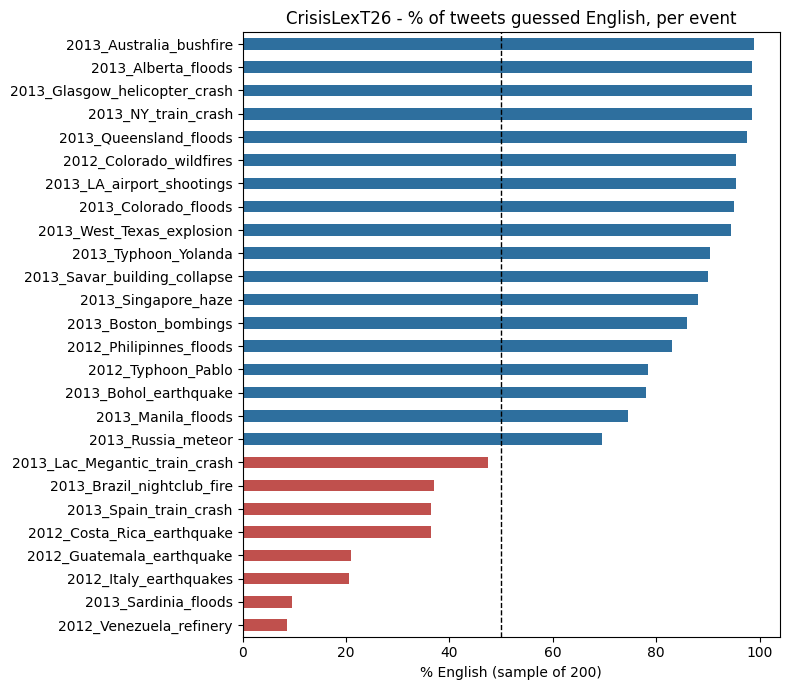

events with less than 50% English: ['2012_Venezuela_refinery', '2013_Sardinia_floods', '2012_Italy_earthquakes', '2012_Guatemala_earthquake', '2012_Costa_Rica_earthquake', '2013_Spain_train_crash', '2013_Brazil_nightclub_fire', '2013_Lac_Megantic_train_crash']


In [29]:
from src.preprocessing.language import guess_language
per_event = {}
for ev, g in crisislex.groupby("event_name"):
    langs = g["Tweet Text"].sample(min(200, len(g)), random_state=0).map(guess_language)
    other = langs[langs != "en"].value_counts()
    per_event[ev] = {"rows": len(g), "english_pct": round(float((langs == "en").mean() * 100), 1),
                     "top_non_english": other.index[0] if len(other) else "-"}
lang_ev = pd.DataFrame(per_event).T.sort_values("english_pct")
lang_ev["english_pct"] = lang_ev["english_pct"].astype(float)
display(lang_ev)

fig, ax = plt.subplots(figsize=(8, 7))
lang_ev["english_pct"].plot.barh(ax=ax, color=["#C0504D" if v < 50 else "#2E6F9E" for v in lang_ev["english_pct"]])
ax.axvline(50, color="k", ls="--", lw=1); ax.set(title="CrisisLexT26 - % of tweets guessed English, per event", xlabel="% English (sample of 200)")
plt.tight_layout(); plt.savefig(E.EDA_DIR / "crisislex_language_by_event.png", dpi=110); plt.show()

mostly_non_english = lang_ev.index[lang_ev["english_pct"] < 50].tolist()
print("events with less than 50% English:", mostly_non_english)
summary["D7_language_by_event"] = {"events_under_50pct_english": mostly_non_english,
                                   "overall_english_pct_sample": round(float(lang_ev["english_pct"].mul(lang_ev["rows"].astype(int)).sum() / lang_ev["rows"].astype(int).sum()), 1)}

---
# SECTION E - Cross-dataset comparison

## E1 - Vocabulary overlap with HumAID
Type coverage = share of a dataset's distinct tokens that exist in HumAID's training vocabulary; OOV = share of its token *occurrences* that do not.

In [30]:
types = {n: {t for x in cleaned[n] for t in tokenize_for_vocabulary(x)} for n in ("kaggle_raw", "crisislex", "humaid_test")}
cov = pd.DataFrame({n: {"distinct token types": len(t), "types covered by HumAID vocab %": round(len(t & set(vocab)) / len(t) * 100, 1),
                        "token OOV %": oov[n]["oov_rate_pct"]} for n, t in types.items()}).T
display(cov); summary["E1_vocab_coverage"] = cov.to_dict("index")

,distinct token types,types covered by HumAID vocab %,token OOV %
kaggle_raw,15072.0,52.8,10.42
crisislex,36698.0,27.2,19.47
humaid_test,23834.0,57.7,2.99


## E2 - Length overlay vs the chosen `max_len`
The overlay histogram is in **A8**. The table below states, per dataset, how much a fixed `max_len` would truncate - and therefore whether a length chosen from HumAID alone is safe for the others.

In [31]:
trunc = pd.DataFrame({n: {"tokens p99": profiles[n]["project_token_length"]["p99"],
                          f"% truncated at BiLSTM max_len={BILSTM_MAX_SEQUENCE_LENGTH}": profiles[n]["pct_over_bilstm_max_len"]}
                      for n in ("humaid_train", "kaggle_raw", "crisislex")}).T
display(trunc)
print(f"BERTweet is capped at {BERTWEET_MAX_LENGTH} tokens (model limit); run_bertweet.py reports the exact truncation counts with the real tokenizer.")
summary["E2_truncation"] = trunc.to_dict("index")

,tokens p99,% truncated at BiLSTM max_len=64
humaid_train,57.0,0.133
kaggle_raw,32.0,0.000
crisislex,33.0,0.011


BERTweet is capped at 128 tokens (model limit); run_bertweet.py reports the exact truncation counts with the real tokenizer.


## E3 - Label taxonomy feasibility: CrisisLexT26 -> HumAID
Data-driven version of the mapping used by `run_crisislex_preprocessing.py` (mapping lives in `src/preprocessing/labels.py`).
* `rough` mappings are flagged and never treated as confirmed ground truth.
* CrisisLexT26 has no counterpart for three HumAID classes, so class-level evaluation can only cover the rest.
* The `Informativeness` dimension ("Not related" vs "Related ...") is used separately, to evaluate the **Kaggle pre-filter**.

In [32]:
it = crisislex["Information Type"].astype(str).str.strip().value_counts().rename("rows").to_frame()
it["humaid_class"] = [CRISISLEX_LABEL_MAP.get(k, (None, "missing"))[0] for k in it.index]
it["mapping_quality"] = [CRISISLEX_LABEL_MAP.get(k, (None, "missing"))[1] for k in it.index]
display(it)
print(it.groupby("mapping_quality")["rows"].sum().to_dict())

covered = set(it["humaid_class"].dropna())
no_counterpart = sorted(set(humaid["train"]["class_label"]) - covered)
print("\nHumAID classes with NO CrisisLexT26 counterpart:", no_counterpart)

inf = crisislex["Informativeness"].astype(str).str.strip().value_counts().rename("rows").to_frame()
inf["prefilter_label"] = [CRISISLEX_PREFILTER_MAP.get(k, "unlabeled") for k in inf.index]
print("\nPre-filter evaluation labels from Informativeness:"); display(inf)
summary["E3_mapping"] = {"rows_by_quality": it.groupby("mapping_quality")["rows"].sum().to_dict(),
                         "humaid_classes_without_counterpart": no_counterpart,
                         "prefilter_rows": {str(k): int(v) for k, v in inf.groupby("prefilter_label")["rows"].sum().items()}}

,rows,humaid_class,mapping_quality
Information Type,,,
Other Useful Information,7627,other_relevant_information,rough
Affected individuals,4790,injured_or_dead_people,rough
Sympathy and support,4650,sympathy_and_support,good
Not labeled,3419,None,unmapped
Donations and volunteering,2404,rescue_volunteering_or_donation_effort,good
Caution and advice,2306,caution_and_advice,good
Infrastructure and utilities,1599,infrastructure_and_utility_damage,good
Not applicable,1138,not_humanitarian,rough


{'good': 10959, 'rough': 13555, 'unmapped': 3419}

HumAID classes with NO CrisisLexT26 counterpart: ['displaced_people_and_evacuations', 'missing_or_found_people', 'requests_or_urgent_needs']

Pre-filter evaluation labels from Informativeness:


,rows,prefilter_label
Informativeness,,
Related and informative,16849,1
Related - but not informative,7732,1
Not related,2863,0
Not applicable,489,unlabeled


## E4 - Preprocessing equivalence: 5 random rows per dataset through the production cleaners
Same function for all three datasets -> any later score difference is not a cleaning artifact. Left: raw. Middle: TF-IDF/BiLSTM path. Right: transformer path.

In [33]:
for name, s in (("HumAID", texts["humaid_train"]), ("Kaggle", texts["kaggle_raw"]), ("CrisisLexT26", texts["crisislex"])):
    rows = s.sample(5, random_state=11)
    print(f"##### {name}")
    display(pd.DataFrame({"raw": rows.str[:85].values, "tfidf/bilstm path": rows.map(clean_tweet_for_tfidf).str[:85].values,
                          "transformer path": rows.map(prepare_tweet_for_transformer).str[:85].values}))

empties = pd.DataFrame({n: {"empty after tfidf cleaning": p["empty_after_tfidf_cleaning"],
                            "empty after transformer cleaning": p["empty_after_transformer_cleaning"],
                            "no letters/digits left": p["no_letters_or_digits_after_cleaning"]} for n, p in profiles.items()})
display(empties)

##### HumAID


,raw,tfidf/bilstm path,transformer path
0,"Flood-hit Kerala sounds alert for leptospirosis, 28 deaths, Unprecedented rain and f","flood-hit kerala sounds alert for leptospirosis, 28 deaths, unprecedented rain and fl","Flood-hit Kerala sounds alert for leptospirosis, 28 deaths, Unprecedented rain and fl"
1,@nytimes The little girl Frida Sofía is under stones in primary damaged by earthquake,usertoken the little girl frida sofía is under stones in primary damaged by earthquak,@nytimes The little girl Frida Sofía is under stones in primary damaged by earthquake
2,MDC leader Nelson Chamisa at Birchnough bridge today en-route to assess Cyclone Idai,mdc leader nelson chamisa at birchnough bridge today en-route to assess cyclone idai,MDC leader Nelson Chamisa at Birchnough bridge today en-route to assess Cyclone Idai
3,Gov McMaster at Noon today declared a state of emergency for #SouthCarolina because o,gov mcmaster at noon today declared a state of emergency for southcarolina because of,Gov McMaster at Noon today declared a state of emergency for #SouthCarolina because o
4,RT @NWSEureka: NO tsunami expected on the west coast of North America:,no tsunami expected on the west coast of north america:,NO tsunami expected on the west coast of North America:


##### Kaggle


,raw,tfidf/bilstm path,transformer path
0,Early wake up call from my sister begging me to come over &amp; ride w/her in the amb,early wake up call from my sister begging me to come over & ride w/her in the ambulan,Early wake up call from my sister begging me to come over & ride w/her in the ambulan
1,Cabin Fever 2 flames https://t.co/yXnagsqvBM,cabin fever 2 flames urltoken,Cabin Fever 2 flames https://t.co/yXnagsqvBM
2,Look down upon three methods touching obtaing rank electrical transcription detonatio,look down upon three methods touching obtaing rank electrical transcription detonatio,Look down upon three methods touching obtaing rank electrical transcription detonatio
3,PIERCE THE VEIL Rubber Bracelet Wristband Collide with the Sky - Full read by eBay ht,pierce the veil rubber bracelet wristband collide with the sky - full read by ebay ur,PIERCE THE VEIL Rubber Bracelet Wristband Collide with the Sky - Full read by eBay ht
4,@sholt87 @MtGrotto @Eco11C @carlsbadbugkil1 Saved us?Bush lowered tax rate for wealth,usertoken usertoken usertoken usertoken saved us?bush lowered tax rate for wealthy n,@sholt87 @MtGrotto @Eco11C @carlsbadbugkil1 Saved us?Bush lowered tax rate for wealth


##### CrisisLexT26


,raw,tfidf/bilstm path,transformer path
0,RT @WLTX: #BREAKING: Gunfire reported Los Angeles airport (#LAX) terminal 3. Pic via,breaking: gunfire reported los angeles airport (lax) terminal 3. pic via fox sports r,#BREAKING: Gunfire reported Los Angeles airport (#LAX) terminal 3. Pic via Fox Sports
1,PSI 198?? Do they seriously think we'd buy that load of crap #sghaze,psi 198?? do they seriously think we'd buy that load of crap sghaze,PSI 198?? Do they seriously think we'd buy that load of crap #sghaze
2,office suspended again. excited pa naman akong pumasok. wala na akong allowance nito.,office suspended again. excited pa naman akong pumasok. wala na akong allowance nito.,office suspended again. excited pa naman akong pumasok. wala na akong allowance nito.
3,"RT @addusamahan: Ateneans, be on the lookout: http://t.co/oA1cRT6n #PabloPh","ateneans, be on the lookout: urltoken pabloph","Ateneans, be on the lookout: http://t.co/oA1cRT6n #PabloPh"
4,Donate to Philippine Flood Victims With Xoom http://t.co/0ZNCOsI4jZ,donate to philippine flood victims with xoom urltoken,Donate to Philippine Flood Victims With Xoom http://t.co/0ZNCOsI4jZ


,humaid_train,humaid_validation,humaid_test,kaggle_raw,crisislex
empty after tfidf cleaning,0,0,0,0,0
empty after transformer cleaning,0,0,0,0,0
no letters/digits left,0,0,0,0,0


---
# Scorecard - every EDA checklist item, its measured finding, and the decision it drives
Built from the measurements above and saved to `docs/eda/eda_summary.json` and `docs/eda/eda_checklist_scorecard.csv`.

In [34]:
P = profiles
def per(key, names=("humaid_train", "kaggle_raw", "crisislex")):
    return " | ".join(f"{n.split('_')[0]} {P[n][key]}" for n in names)

q = summary["C_quality"]; s = summary
rows = [
 ("A1",  "Row counts", "all five counts match the documented values", "none"),
 ("A2",  "Null / empty text", per("null_text") + " (nulls); " + per("empty_text") + " (empty)", "none - no missing text"),
 ("A3",  "Exact duplicate rows", per("exact_duplicate_rows"), "Kaggle + CrisisLex deduplicated / flagged in the pipeline"),
 ("A4",  "Near-duplicate rows", per("near_duplicate_rows"), "same key (normalize_for_dedup) used for dedup + leakage guard"),
 ("A5",  "Empty after cleaning", per("empty_after_tfidf_cleaning") + " empty; no-letters: " + per("no_letters_or_digits_after_cleaning"), "no row needs special handling"),
 ("A6",  "HTML entities", per("html_entity_rows") + " raw -> " + per("html_entity_rows_after_cleaning") + " after cleaning", "explicit unescape step (repeated) in text_cleaning"),
 ("A7",  "Apostrophe-less contractions / elongations", per("apostrophe_less_contraction_rows") + " / " + per("elongated_word_rows"), "left as-is, same rule for every dataset"),
 ("A7b", "Encoding damage (mojibake)", per("encoding_damage_rows"), "fix_mojibake in the shared cleaner (only Kaggle affected)"),
 ("A8",  "Length percentiles", "token p99: " + " | ".join(f"{n.split('_')[0]} {P[n]['project_token_length']['p99']:.0f}" for n in ("humaid_train", "kaggle_raw", "crisislex")), f"BiLSTM max_len={BILSTM_MAX_SEQUENCE_LENGTH}; BERTweet {BERTWEET_MAX_LENGTH}"),
 ("A9",  "OOV vs HumAID-train vocab", " | ".join(f"{n.split('_')[0]} {s['A9_oov_vs_humaid_train_vocab'][n]['oov_rate_pct']}%" for n in ("humaid_test", "kaggle_raw", "crisislex")), "CrisisLex shift is large - expected for a 2012-13 external test"),
 ("A10", "Language", " | ".join(f"{n.split('_')[0]} en={s['A10_language_sample_pct'][n].get('en', 0)}%" for n in s["A10_language_sample_pct"]), "HumAID/Kaggle are English; CrisisLexT26 is multilingual (see D7) -> language_guess flag, English-only evaluation"),
 ("A11", "Hashtag dominance (top-1 share)", " | ".join(f"{n.split('_')[0]} {P[n]['hashtags']['top1_share_pct']}%" for n in ('humaid_train', 'kaggle_raw', 'crisislex')), "no single hashtag drives a dataset"),
 ("A12", "Mentions / URLs", " | ".join(f"{n.split('_')[0]} {P[n]['mentions']['mean_per_row']}@ {P[n]['urls']['mean_per_row']}url" for n in ('humaid_train', 'kaggle_raw', 'crisislex')), "placeholders in the TF-IDF path"),
 ("A13", "Emoji", " | ".join(f"{n.split('_')[0]} {P[n]['emoji']['rows_with']} rows" for n in ('humaid_train', 'kaggle_raw', 'crisislex')), "TF-IDF pattern keeps emoji; transformer path demojizes"),
 ("A14", "Tweet IDs", f"Kaggle dup IDs {P['kaggle_raw']['ids']['duplicate_ids']}; CrisisLex dup IDs {P['crisislex']['ids']['duplicate_ids']}, IDs with different text {P['crisislex']['ids']['ids_with_different_texts']}; HumAID has no ID column", "documented N/A for HumAID"),
 ("A15", "Manual reading", "15 random rows per dataset + 15 per HumAID class read", "notes recorded in docs"),
 ("B1",  "HumAID class distribution", f"10 classes; largest {int(dist['train'].max())} / smallest {int(dist['train'].min())}", "class-weighted loss in training"),
 ("B2",  "Imbalance ratio", f"{s['B_class_distribution']['imbalance_ratio']}", "weighted loss / oversampling + macro-F1"),
 ("B3",  "Event vs label", "no event column in the CSVs; disaster-type keyword proxy only", "limitation documented; add event files if obtainable"),
 ("B4",  "Split consistency", f"max class-share gap {s['B_class_distribution']['max_gap_train_val_pp']:.2f} pp (val), {s['B_class_distribution']['max_gap_train_test_pp']:.2f} pp (test)", "splits are consistent"),
 ("B5",  "Cross-split leakage", " | ".join(f"{k}: {v['rows_in_second_with_near_twin']} rows" for k, v in s["B5_split_overlap"].items()), "official splits untouched; overlap disclosed"),
 ("B6",  "Rare classes (<500 train rows)", str(s["B_class_distribution"]["classes_under_500_train"]), "flagged for imbalance handling"),
 ("B7",  "dont_know_cant_judge vs not_humanitarian", "dont_know_cant_judge is absent from the data -> N/A; read not_humanitarian vs other_relevant_information instead", "documented"),
 ("C1",  "Kaggle target balance (raw)", str({k: v['percent'] for k, v in s['C1_target_balance_raw'].items()}), "stratified split"),
 ("C2",  "keyword column", f"{s['C2_keyword']['missing_pct']}% missing; {s['C2_keyword']['pure_keywords_ge10_rows']} pure keywords; {s['C2_keyword']['pct_keywords_extreme_rate']}% of keywords have an extreme disaster rate", "keyword NOT used as a feature (shortcut risk)"),
 ("C3",  "location column", f"{s['C3_location']['missing_pct']}% missing; {s['C3_location']['pct_values_occurring_once']}% of values unique", "location NOT used (free text)"),
 ("C4",  "Hard negatives", f"{s['C4_hard_negatives']} non-disaster tweets contain disaster words", "this is the signal the pre-filter must learn"),
 ("C5",  "Only labeled file used", f"unlabeled competition file has target: {s['C5_unlabeled_file_has_target']}", "enforced by verify_pipeline C7"),
 ("C6",  "Length by target", str(s['C6_length_by_target_mean']), "no strong length shortcut"),
 ("C-q", "Duplicates / conflicts / leakage", f"{q['exact_duplicate_rows']} exact dup, {q['near_duplicate_rows']} near-dup, {q['conflicting_label_groups']} conflicting groups; a naive split leaks {q['naive_split_val_rows_with_twin_in_train']} val + {q['naive_split_test_rows_with_twin_in_train']} test rows", f"dedupe before split -> {q['rows_after_pipeline_dedup']} rows"),
 ("D1",  "Schema across 26 files", f"{s['D1_distinct_schemas']} distinct column layout(s)", "safe to concatenate"),
 ("D2",  "Text vs IDs", f"{s['D2_text_present_pct']}% of rows have full text", "no rehydration needed"),
 ("D3",  "Three label dimensions", "Informativeness, Information Type, Information Source analysed separately + crosstab", "Type -> 11-class eval; Informativeness -> pre-filter eval"),
 ("D4",  "Event distribution", f"{s['D4_events']['events']} events; largest {s['D4_events']['largest_share_pct']}% of rows", "no single event dominates"),
 ("D5",  "Era vocabulary shift", f"top-5k token Jaccard {s['D5_era_shift']['top5000_token_jaccard']}; shared top-20 hashtags {len(s['D5_era_shift']['shared_top20_hashtags'])}", "robustness drop is expected and will be reported"),
 ("D6",  "event_name retained", "event_name column present for all rows", "verified by verify_pipeline D6"),
 ("D7",  "Language by event", f"{len(s['D7_language_by_event']['events_under_50pct_english'])} of 26 events are under 50% English: {', '.join(e.replace('_', ' ') for e in s['D7_language_by_event']['events_under_50pct_english'][:4])}...", "language_guess + English-only evaluation flags in the pipeline"),
 ("E1",  "Vocabulary overlap", " | ".join(f"{n.split('_')[0]} OOV {v['token OOV %']}%" for n, v in s['E1_vocab_coverage'].items()), "reported in docs/oov_audit.json"),
 ("E2",  "Length overlay vs max_len", "overlay in A8; truncation table in E2", f"max_len {BILSTM_MAX_SEQUENCE_LENGTH} safe for all three"),
 ("E3",  "Taxonomy feasibility", f"{s['E3_mapping']['rows_by_quality']}; no counterpart for {s['E3_mapping']['humaid_classes_without_counterpart']}", "evaluate on the 7 mapped classes; Informativeness -> pre-filter test"),
 ("E4",  "Preprocessing equivalence", "5 random rows per dataset through the same production cleaners", "identical rules for all three"),
]
scorecard = pd.DataFrame(rows, columns=["Item", "Check", "Measured finding", "Decision / action"])
display(scorecard)
scorecard.to_csv(E.EDA_DIR / "eda_checklist_scorecard.csv", index=False)
(E.EDA_DIR / "eda_summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print(f"\n{len(scorecard)} checklist rows written to {E.EDA_DIR.relative_to(ROOT)}/")

,Item,Check,Measured finding,Decision / action
0,A1,Row counts,all five counts match the documented values,none
1,A2,Null / empty text,humaid 0 | kaggle 0 | crisislex 0 (nulls); humaid 0 | kaggle 0 | crisislex 0 (empty),none - no missing text
2,A3,Exact duplicate rows,humaid 0 | kaggle 110 | crisislex 2625,Kaggle + CrisisLex deduplicated / flagged in the pipeline
3,A4,Near-duplicate rows,humaid 2 | kaggle 777 | crisislex 3647,same key (normalize_for_dedup) used for dedup + leakage guard
4,A5,Empty after cleaning,humaid 0 | kaggle 0 | crisislex 0 empty; no-letters: humaid 0 | kaggle 0 | crisislex 0,no row needs special handling
5,A6,HTML entities,humaid 4886 | kaggle 359 | crisislex 1259 raw -> humaid 0 | kaggle 0 | crisislex 0 after cleaning,explicit unescape step (repeated) in text_cleaning
6,A7,Apostrophe-less contractions / elongations,humaid 2658 | kaggle 109 | crisislex 91 / humaid 288 | kaggle 133 | crisislex 390,"left as-is, same rule for every dataset"
7,A7b,Encoding damage (mojibake),humaid 0 | kaggle 669 | crisislex 0,fix_mojibake in the shared cleaner (only Kaggle affected)
8,A8,Length percentiles,token p99: humaid 57 | kaggle 32 | crisislex 33,BiLSTM max_len=64; BERTweet 128
9,A9,OOV vs HumAID-train vocab,humaid 2.99% | kaggle 10.42% | crisislex 19.47%,CrisisLex shift is large - expected for a 2012-13 external test



41 checklist rows written to docs/eda/
